# Loan Prediction Project

In this project, we will use borrower data to predict whether a loan was fully paid back or not.
We will compare a decision tree and a random forest model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
loans = pd.read_csv('loan_data.csv')
print(loans.head())
print(loans.info())
print(loans.describe())

   credit.policy             purpose  int.rate  installment  log.annual.inc  \
0              1  debt_consolidation    0.1189       829.10       11.350407   
1              1         credit_card    0.1071       228.22       11.082143   
2              1  debt_consolidation    0.1357       366.86       10.373491   
3              1  debt_consolidation    0.1008       162.34       11.350407   
4              1         credit_card    0.1426       102.92       11.299732   

     dti  fico  days.with.cr.line  revol.bal  revol.util  inq.last.6mths  \
0  19.48   737        5639.958333      28854        52.1               0   
1  14.29   707        2760.000000      33623        76.7               0   
2  11.63   682        4710.000000       3511        25.6               1   
3   8.10   712        2699.958333      33667        73.2               1   
4  14.97   667        4066.000000       4740        39.5               0   

   delinq.2yrs  pub.rec  not.fully.paid  
0            0        0   

## Step 1: Explore the data

We check the structure of the dataset and inspect the columns.

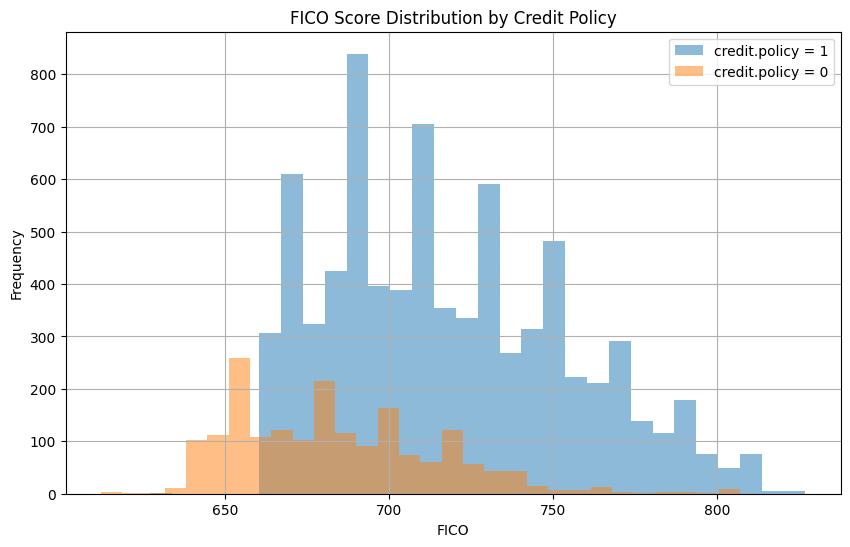

In [3]:
plt.figure(figsize=(10,6))
loans[loans['credit.policy'] == 1]['fico'].hist(alpha=0.5, bins=30, label='credit.policy = 1')
loans[loans['credit.policy'] == 0]['fico'].hist(alpha=0.5, bins=30, label='credit.policy = 0')
plt.title('FICO Score Distribution by Credit Policy')
plt.xlabel('FICO')
plt.ylabel('Frequency')
plt.legend()
plt.show()

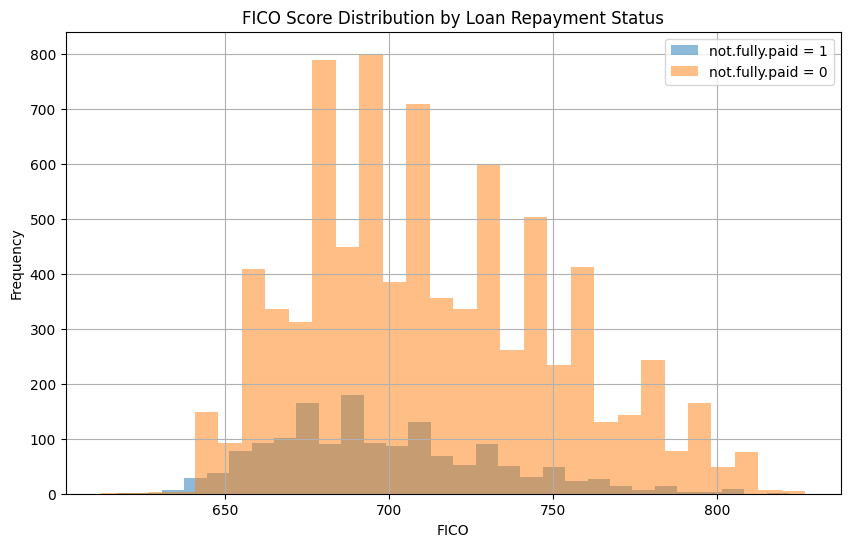

In [4]:
plt.figure(figsize=(10,6))
loans[loans['not.fully.paid'] == 1]['fico'].hist(alpha=0.5, bins=30, label='not.fully.paid = 1')
loans[loans['not.fully.paid'] == 0]['fico'].hist(alpha=0.5, bins=30, label='not.fully.paid = 0')
plt.title('FICO Score Distribution by Loan Repayment Status')
plt.xlabel('FICO')
plt.ylabel('Frequency')
plt.legend()
plt.show()

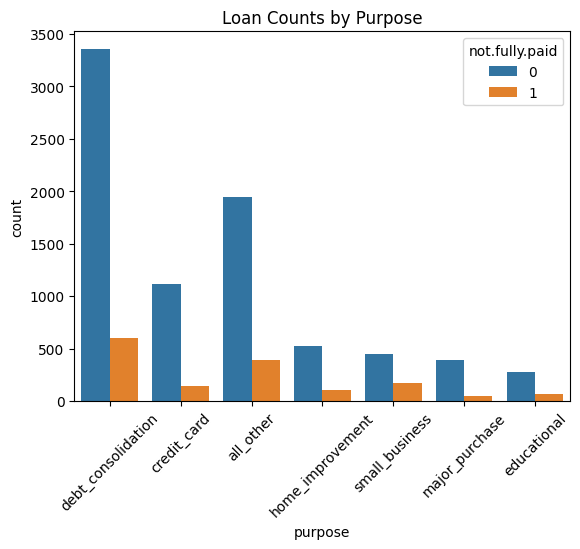

In [5]:
sns.countplot(data=loans, x='purpose', hue='not.fully.paid')
plt.title('Loan Counts by Purpose')
plt.xticks(rotation=45)
plt.show()

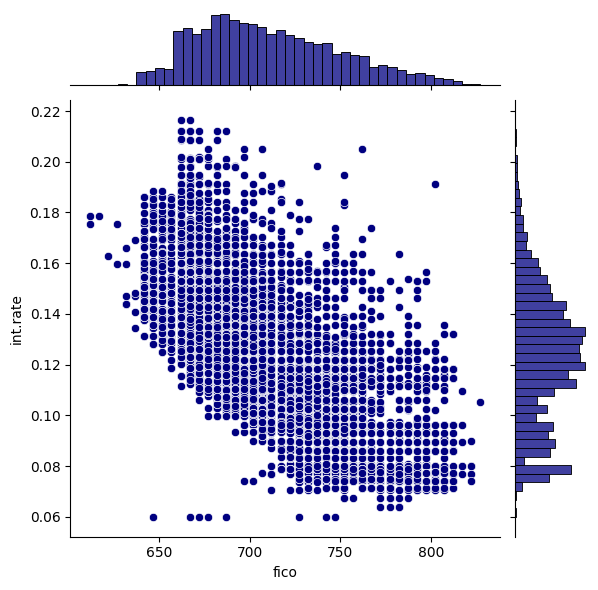

In [6]:
sns.jointplot(x='fico', y='int.rate', data=loans, kind='scatter', color='navy')
plt.show()

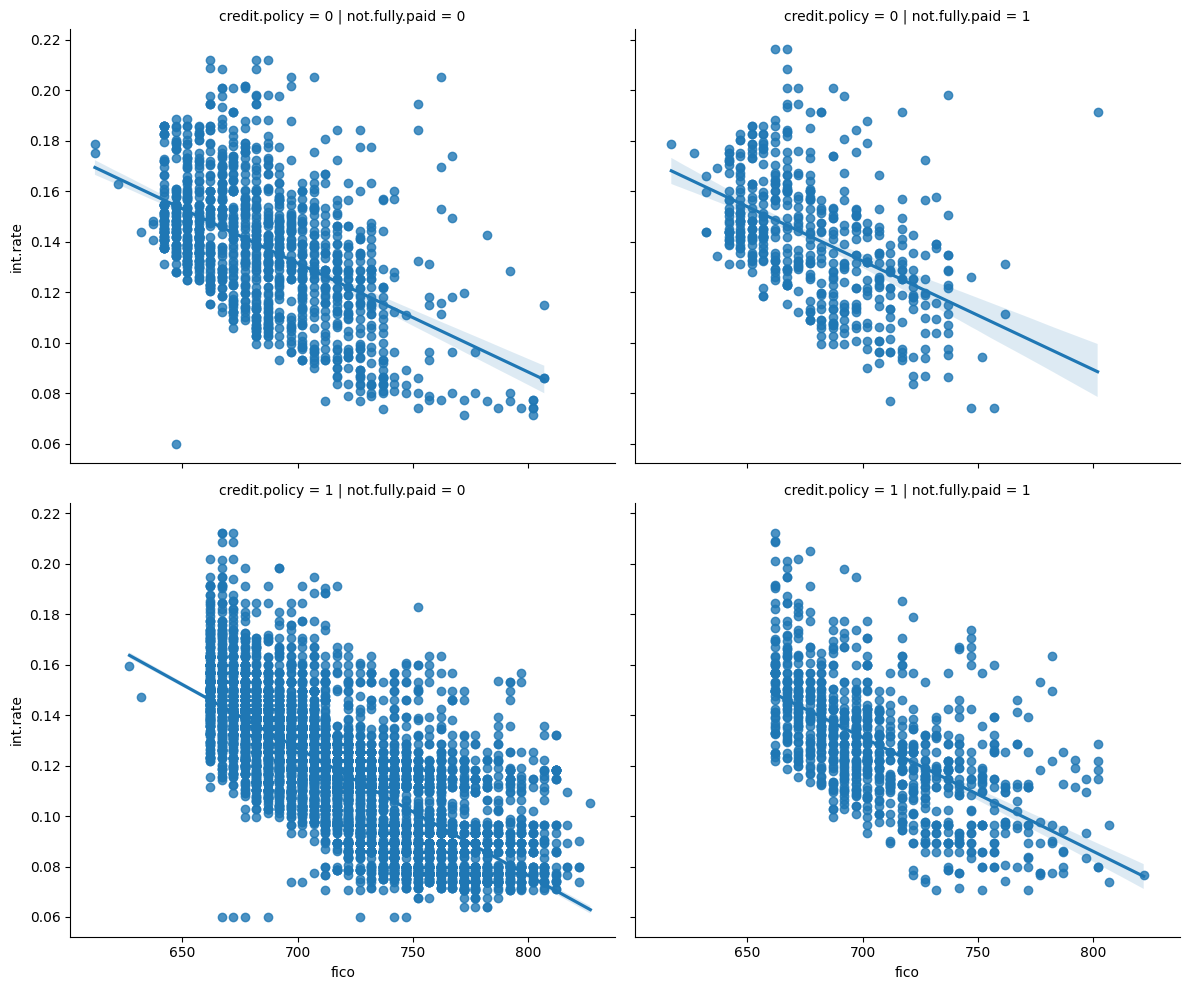

In [7]:
sns.lmplot(data=loans, x='fico', y='int.rate', col='not.fully.paid', row='credit.policy', aspect=1.2)
plt.show()

## Step 2: Prepare the data for machine learning

The column `purpose` is categorical, so we convert it into dummy variables using `pd.get_dummies`.

In [9]:
cat_feats = ['purpose']
final_data = pd.get_dummies(loans, columns=cat_feats, drop_first=True)

X = final_data.drop('not.fully.paid', axis=1)
y = final_data['not.fully.paid']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=101,
)

## Step 3: Train a Decision Tree

A single decision tree is a good starting point because it is easy to understand.

In [10]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train, y_train)

dt_predictions = dtree.predict(X_test)
print(classification_report(y_test, dt_predictions))
print(confusion_matrix(y_test, dt_predictions))

              precision    recall  f1-score   support

           0       0.86      0.82      0.84      2431
           1       0.19      0.24      0.21       443

    accuracy                           0.73      2874
   macro avg       0.52      0.53      0.53      2874
weighted avg       0.75      0.73      0.74      2874

[[1991  440]
 [ 337  106]]


## Step 4: Train a Random Forest

A random forest combines multiple decision trees to reduce overfitting and often improve accuracy.

In [11]:
rfc = RandomForestClassifier(n_estimators=600)
rfc.fit(X_train, y_train)

rf_predictions = rfc.predict(X_test)
print(classification_report(y_test, rf_predictions))
print(confusion_matrix(y_test, rf_predictions))

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2431
           1       0.44      0.02      0.03       443

    accuracy                           0.85      2874
   macro avg       0.65      0.51      0.48      2874
weighted avg       0.79      0.85      0.78      2874

[[2421   10]
 [ 435    8]]


## Step 5: Compare results

We compare the classification report and confusion matrix from both models.
Random forests often perform better than a single decision tree because they aggregate many trees.